# 3. BTC MONDAY EFFECT - ROBUSTNESS BATTERY & VALIDATION GATE

This notebook runs the multi-phase robustness battery and the validation gate for the **BTC Monday Effect (v3)** on hourly BTC/USDT bars, following the structure of notebook 03 of the RSI2 edge. The rules are the ones frozen in notebooks 01 and 02: nothing is re-tuned here.

### ROBUSTNESS BATTERY SCOPE
1. **Phase 1 · Out-Of-Sample**: untouched data since `split.oos_start` (2024-01-08).
2. **Phase 2 · Walk-Forward (fixed rules, 3y IS / 1y OOS)**.
3. **Phase 3 · Block Monte Carlo**: 10,000 circular block resamplings (block = 5), at the robot's 40 % sizing and at 30 %.
4. **Phase 4 · Monkey Test**: (A) random 24 h long entries at any hour; (B) random choice among all Mondays (does the filter beat picking Mondays at random?).
5. **Phase 5 · Stress**: costs x2, cost break-even sweep (what matters for Darwinex / Axi), best-years removal, bear regimes, profit concentration.
6. **Phase 6 · Edge Decay**: rolling PF, PF by year, and the z wear-and-tear protocol (last 20 traded Mondays vs reference).
7. **Phase 7 · Full Validation Gate** via `validation_gate.run_validation`.

### STRATEGY PARAMETERS

In [5]:
VARIANT = "v1_btcusd"  # only base variants here; see variants/*.yaml

## 1. IMPORTS AND CONFIG

In [6]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
from robustness import monte_carlo_block, monkey_test, grid_search, plateau_check, plot_grid, plot_monkey, profit_factor
from edge_decay import rolling_pf, plot_rolling_pf, pf_by_year, edge_decay_summary
from validation_gate import run_validation, DEFAULTS as GATE
import monday_effect_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
VOL_MODE, ATR_PCTL, ATR_LEN = P["vol_mode"], float(P["atr_pctl"]), int(P["atr_len"])
SKIP1, ENTRY_HOUR, HOLD, COST_BPS = P["skip_first_monday"], P["entry_hour"], P["hold_bars"], P["cost_bps_per_side"]
PCTLS      = [float(x) for x in cfg["grid"]["atr_pctl_values"]]
ATR_LENS   = [int(x) for x in cfg["grid"]["atr_len_values"]]
CHOSEN     = (ATR_PCTL, ATR_LEN)
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
PPY        = 365    # BTC trades every day: annualisation for Sharpe
SIZES      = {f"{SIZE_FRAC:.0%} (robot)": SIZE_FRAC, "30%": 0.30}   # first = official run
OFFICIAL   = next(iter(SIZES))

RULES = dict(vol_mode=VOL_MODE, atr_pctl=ATR_PCTL, atr_len=ATR_LEN, skip_first_monday=SKIP1,
             entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)

# ---- Style and helpers (same palette as notebooks 01 and 02) ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRIDC, alpha=0.8)
    ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

ERAS = {"Retail (2017-19)": (2017, 2019), "Institutional (2020-23)": (2020, 2023), "ETF (2024+)": (2024, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def scaled(t, frac):
    """Trades with pnl rescaled to a fraction of capital (pnl in % of equity)."""
    return t.assign(pnl=t["pnl"] * frac, win=t["pnl"] * frac > 0)

print("Imports complete.")
print(f"Loaded monday_effect_engine from: {eng.__file__}")
print(f"Variant: {cfg['id']} | {TICKER} | ATR({ATR_LEN})% >= P{ATR_PCTL:g} | skip first Monday={SKIP1} | {COST_BPS:g} bps/side | sizes {list(SIZES)}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded monday_effect_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/monday_effect_engine.py
Variant: MONDAY.btcusd.cfd.v1 | btcusd | ATR(24)% >= P40 | skip first Monday=True | 5.5 bps/side | sizes ['20% (robot)', '30%']
Data source: csv_hourly | swap: 4.11 bps/night
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd


## 2. OUT-OF-SAMPLE (OOS) PERFORMANCE & COMPARISON

Indicators are computed once on the full history so the OOS slice keeps the percentile warm-up (same as notebook 01).

OOS PERFORMANCE & COMPARISON (NET OF 5.5 BPS PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2017-2024),100% Capital,78,52.6%,1.653,1.172%,115.5%,12.2%,0.66,-29.18%
1,In-Sample (2017-2024),20% Capital (robot),78,52.6%,1.653,0.234%,18.8%,2.6%,0.65,-6.56%
2,Out-of-Sample (2024-2026),100% Capital,40,80.0%,6.451,1.703%,94.0%,26.8%,2.09,-3.61%
3,Out-of-Sample (2024-2026),20% Capital (robot),40,80.0%,6.451,0.341%,14.6%,5.0%,2.12,-0.72%
4,Full Period (2017-2026),100% Capital,118,61.9%,2.047,1.352%,318.0%,16.3%,0.90,-29.18%
5,Full Period (2017-2026),20% Capital (robot),118,61.9%,2.047,0.270%,36.1%,3.3%,0.90,-6.56%


PF IS 1.653 -> OOS 6.451 | OOS without best trade 5.636 | OOS t-stat of the mean 4.10 | OOS trades 40


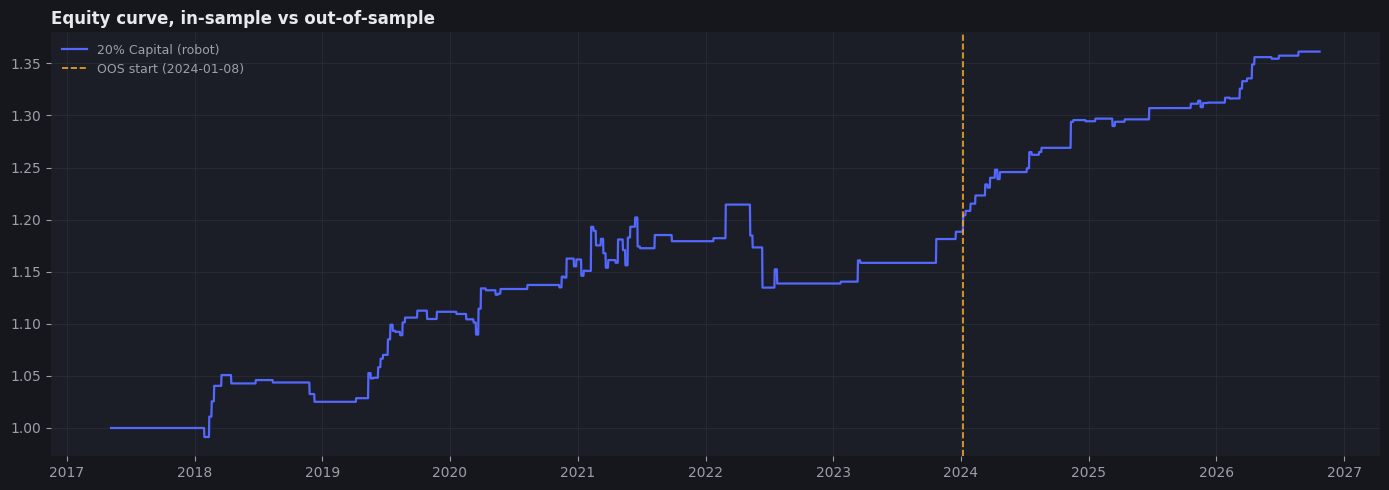

In [7]:
df_raw = eng.load_data(TICKER, start=DATA_START)
preps = {L: eng.prepare(df_raw, atr_len=L, entry_hour=ENTRY_HOUR) for L in ATR_LENS}   # one prepare per ATR length (also used by the gate grid)
df = preps[ATR_LEN]

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
oos_start = df_oos.index[0]

trades_all = eng.run_monday_backtest(df,     **RULES)
trades_is  = eng.run_monday_backtest(df_is,  **RULES)
trades_oos = eng.run_monday_backtest(df_oos, **RULES)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    yrs = (price_df.index[-1] - price_df.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])

print("=" * 80)
print(f"OOS PERFORMANCE & COMPARISON (NET OF {COST_BPS:g} BPS PER SIDE)")
print("=" * 80)
display(perf_table)

m_is, m_oos = compute_metrics(trades_is, 1.0, 0.0), compute_metrics(trades_oos, 1.0, 0.0)
pnl_oos = trades_oos["pnl"].to_numpy(float)
pf_oos_nb = profit_factor(np.delete(pnl_oos, pnl_oos.argmax())) if len(pnl_oos) > 1 else np.nan
print(f"PF IS {m_is['profit_factor']:.3f} -> OOS {m_oos['profit_factor']:.3f} | OOS without best trade {pf_oos_nb:.3f} | "
      f"OOS t-stat of the mean {tstat(pnl_oos):.2f} | OOS trades {len(trades_oos)}")

ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
fig, ax = plt.subplots(figsize=(14, 5), facecolor=BG)
dark_ax(ax)
ax.plot(ret_fr.index, (1 + ret_fr).cumprod(), color="#5468ff", lw=1.6, label=f"{SIZE_FRAC:.0%} Capital (robot)")
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS start ({oos_start:%Y-%m-%d})")
ax.set_title("Equity curve, in-sample vs out-of-sample", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 3. WALK-FORWARD ANALYSIS (FIXED RULES: 3Y IS / 1Y OOS)

Rules are not re-fitted: each calendar year is compared with the annualised return of the three full years before it. The first year of data is partial and never counts as IS, so the first window is 2021. Same gate thresholds as RSI2 (efficiency >= 0.5, positive years >= 60 %, worst year drawdown > -20 %). With only a handful of windows, read it as descriptive.

WALK-FORWARD SUMMARY (6 ROLLING WINDOWS, 20% sizing)
Walk-Forward Efficiency (OOS mean / IS annual mean): 0.846 (>= 0.50)
Positive OOS years ratio: 83.3% (5/6) (>= 60%)
Worst single-year OOS drawdown: -6.56% (> -20%)
Walk-Forward Gate Verdict: PASSED


,year,ret_is_anual,ret_oos,mdd_oos,n_oos
0,2021,0.0512,0.0151,-0.0329,21
1,2022,0.0478,-0.0345,-0.0656,8
2,2023,0.0081,0.0436,-0.0020,5
3,2024,0.0076,0.0893,-0.0072,18
4,2025,0.0315,0.0138,-0.0055,11
5,2026,0.0485,0.0373,-0.0011,11


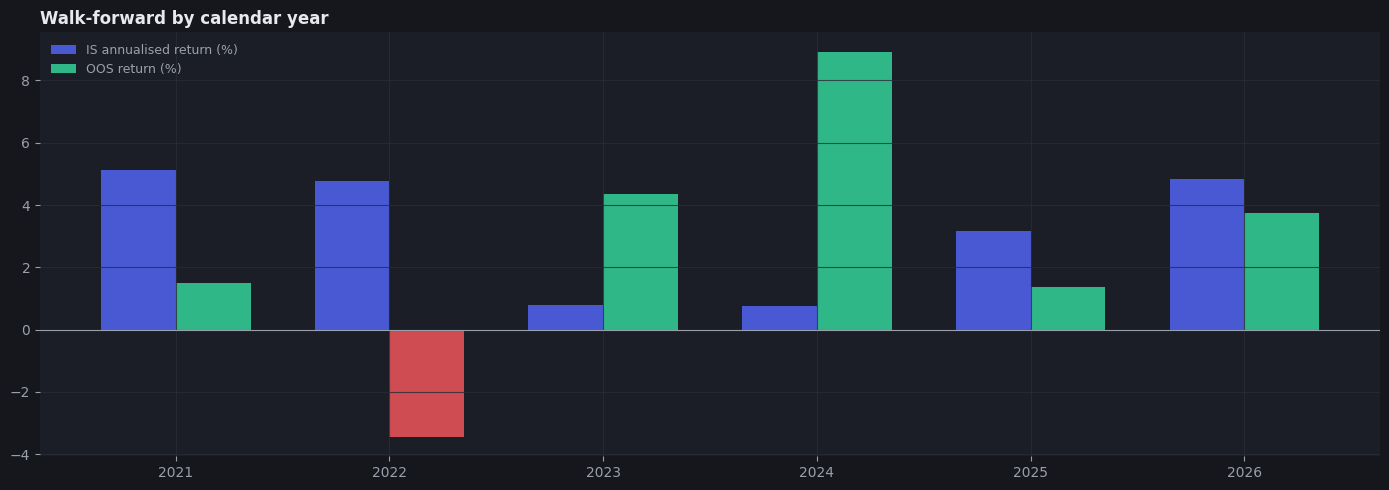

In [8]:
wf_df = eng.walk_forward_fixed(df, rules=RULES, is_years=3, sizing="fraction")
assert len(wf_df) > 0, "No walk-forward windows: need at least 3 full years before the first tested year."

mean_is, mean_oos = wf_df["ret_is_anual"].mean(), wf_df["ret_oos"].mean()
efficiency = mean_oos / mean_is if mean_is > 0 else np.nan
pct_positive_years = float((wf_df["ret_oos"] > 0).mean())
worst_oos_mdd = float(wf_df["mdd_oos"].min())
wf_pass = bool(np.isfinite(efficiency) and efficiency >= 0.5 and pct_positive_years >= 0.60 and worst_oos_mdd > -0.20)

print("=" * 70)
print(f"WALK-FORWARD SUMMARY ({len(wf_df)} ROLLING WINDOWS, {SIZE_FRAC:.0%} sizing)")
print("=" * 70)
print(f"Walk-Forward Efficiency (OOS mean / IS annual mean): {efficiency:.3f} (>= 0.50)")
print(f"Positive OOS years ratio: {pct_positive_years * 100:.1f}% ({int((wf_df['ret_oos'] > 0).sum())}/{len(wf_df)}) (>= 60%)")
print(f"Worst single-year OOS drawdown: {worst_oos_mdd * 100:.2f}% (> -20%)")
print(f"Walk-Forward Gate Verdict: {'PASSED' if wf_pass else 'FAILED'}")
display(wf_df.round(4))

fig, ax = plt.subplots(figsize=(14, 5), facecolor=BG)
dark_ax(ax)
x, w = np.arange(len(wf_df)), 0.35
ax.bar(x - w / 2, wf_df["ret_is_anual"] * 100, w, label="IS annualised return (%)", color="#5468ff", alpha=0.8)
ax.bar(x + w / 2, wf_df["ret_oos"] * 100, w, label="OOS return (%)", color=[GREEN if r > 0 else RED for r in wf_df["ret_oos"]], alpha=0.85)
ax.axhline(0, color=SUB, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(wf_df["year"], color=SUB)
ax.set_title("Walk-forward by calendar year", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 4. BLOCK MONTE CARLO BOOTSTRAP (10,000 SIMULATIONS)

Trades are resampled in blocks of 5 (streaks preserved) and each simulated equity path is built from the **hourly MTM paths** of the sampled trades, so drawdown is measured hour by hour. Run at the robot's sizing and at 30 %; the position size is the only risk control of this edge (no stop), so the size is chosen here.

BLOCK MONTE CARLO SUMMARY (10,000 RUNS, daily-MTM drawdown on hourly paths)


,Median return,p5 return,Median max DD,Worst-5% DD (mdd_p5),Worst simulated DD,Prob. ruin (50% DD),Prob. positive,Real DD of this history
Sizing,,,,,,,,
20% (robot),36.5%,15.7%,-6.96%,-11.17%,-20.07%,0.00%,99.9%,-7.33%
30%,58.8%,24.0%,-10.30%,-16.35%,-28.69%,0.00%,99.8%,-10.81%


Gate limit on mdd_p5: -25% | the published manual accepts a 1-point margin at 40% sizing; shown below in the verdict.


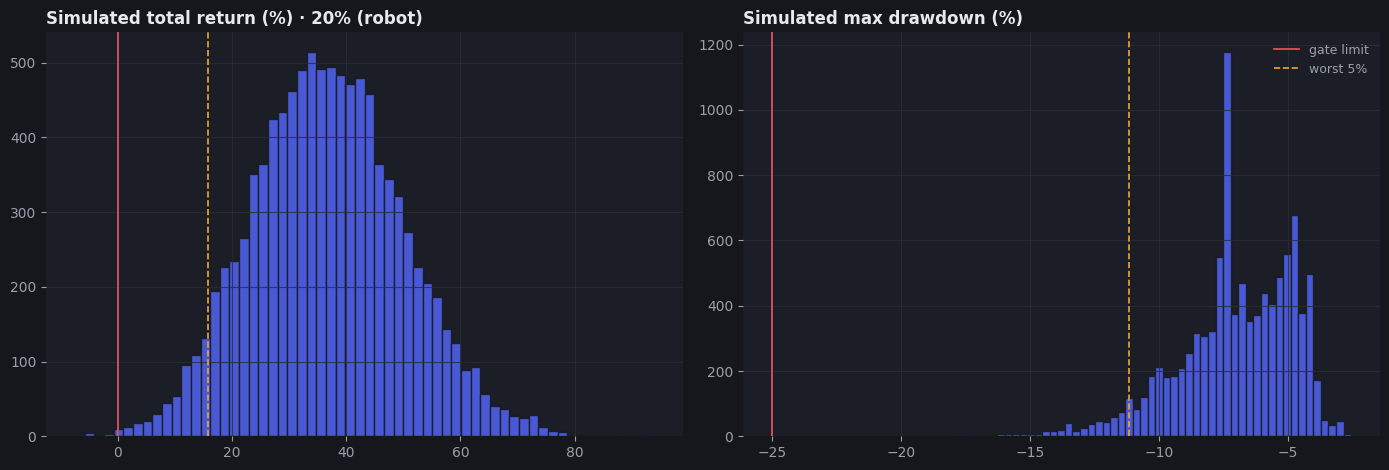

In [9]:
paths = {k: eng.trade_mtm_paths(df, trades_all, sizing=f) for k, f in SIZES.items()}
mcs = {k: monte_carlo_block(scaled(trades_all, f), n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths[k])
       for k, f in SIZES.items()}

rows = []
for k, m in mcs.items():
    rows.append({"Sizing": k, "Median return": f"{m['ret_p50'] * 100:.1f}%", "p5 return": f"{m['ret_p5'] * 100:.1f}%",
                 "Median max DD": f"{m['mdd_p50'] * 100:.2f}%", "Worst-5% DD (mdd_p5)": f"{m['mdd_p5'] * 100:.2f}%",
                 "Worst simulated DD": f"{m['mdd_worst'] * 100:.2f}%", "Prob. ruin (50% DD)": f"{m['prob_ruin'] * 100:.2f}%",
                 "Prob. positive": f"{m['prob_positive'] * 100:.1f}%", "Real DD of this history": f"{m['real_mdd'] * 100:.2f}%"})
print("=" * 70)
print("BLOCK MONTE CARLO SUMMARY (10,000 RUNS, daily-MTM drawdown on hourly paths)")
print("=" * 70)
display(pd.DataFrame(rows).set_index("Sizing"))
print(f"Gate limit on mdd_p5: {GATE['mc_mdd_p5_min'] * 100:.0f}% | the published manual accepts a 1-point margin at 40% sizing; shown below in the verdict.")

mc0 = mcs[OFFICIAL]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), facecolor=BG)
dark_ax(ax1); dark_ax(ax2)
ax1.hist(mc0["rets"] * 100, bins=60, color="#5468ff", alpha=0.8, edgecolor=BG)
ax1.axvline(0, color=RED, lw=1.2); ax1.axvline(mc0["ret_p5"] * 100, color=ORANGE, ls="--", lw=1.2)
ax1.set_title(f"Simulated total return (%) · {OFFICIAL}", color=TXT, fontweight="bold", loc="left")
ax2.hist(mc0["mdds"] * 100, bins=60, color="#5468ff", alpha=0.8, edgecolor=BG)
ax2.axvline(GATE["mc_mdd_p5_min"] * 100, color=RED, lw=1.2, label="gate limit")
ax2.axvline(mc0["mdd_p5"] * 100, color=ORANGE, ls="--", lw=1.2, label="worst 5%")
ax2.set_title("Simulated max drawdown (%)", color=TXT, fontweight="bold", loc="left")
ax2.legend(frameon=False, labelcolor=SUB, fontsize=9)
plt.tight_layout(); plt.show()

## 5. MONKEY TEST (2,000 SYNTHETIC RANDOM PORTFOLIOS)

Same number of trades, same 24-bar holding time, same costs.
- **A · Timing monkey (used by the gate)**: random entry at *any* hourly bar of the history. It rules out that the result is just BTC drift plus holding 24 h.
- **B · Filter monkey (edge-specific)**: random choice among *all* Monday 00:00 entries. It answers whether the volatility and calendar filters pick better Mondays than chance, not only whether Mondays are good.

MONKEY TEST RESULTS
A · timing monkey (any hour): strategy PF 2.047 | monkey median PF 1.060 | beats 99.0% on PF, 100.0% on expectancy (gate >= 95%)
B · filter monkey (any Monday): strategy PF 2.047 | monkey median PF 1.282 | beats 97.9% on PF, 99.7% on expectancy (gate >= 95%)


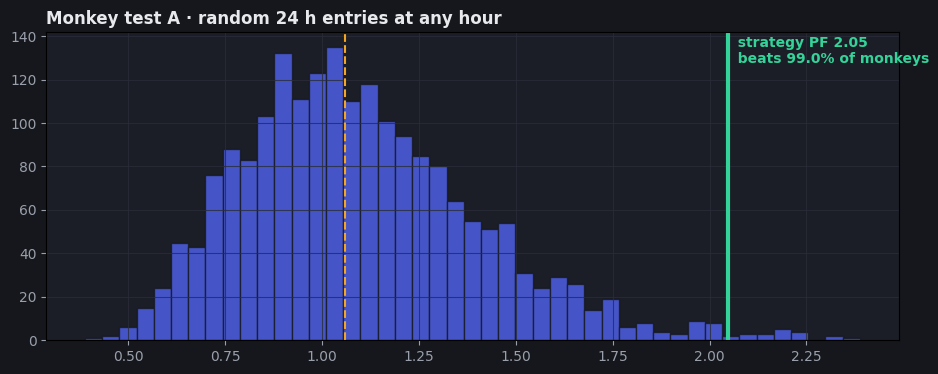

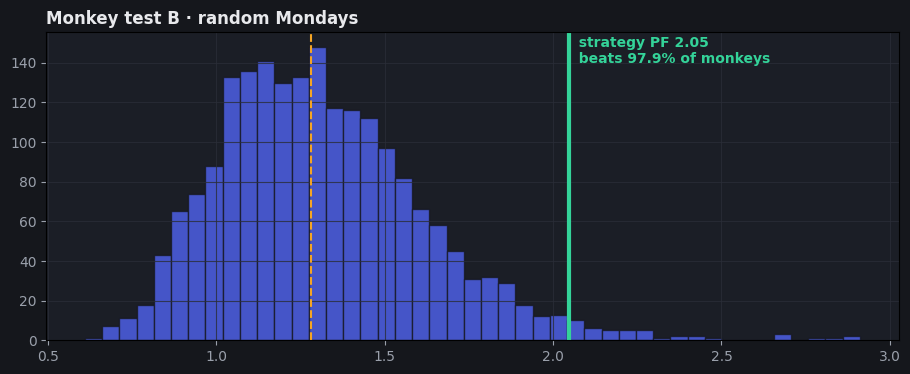

In [10]:
elig_A = pd.Series(True, index=df.index)
elig_B = df["entry_ok"].astype(bool)
mk_kw = dict(n_sim=2000, entry_col="open", exit_col="open", cost_pct_per_side=COST_BPS / 100.0, seed=42)

mk_A = monkey_test(df, trades_all, eligible=elig_A, **mk_kw)
mk_B = monkey_test(df, trades_all, eligible=elig_B, **mk_kw)

print("=" * 70)
print("MONKEY TEST RESULTS")
print("=" * 70)
for name, mk in (("A · timing monkey (any hour)", mk_A), ("B · filter monkey (any Monday)", mk_B)):
    print(f"{name}: strategy PF {mk['pf_real']:.3f} | monkey median PF {mk['pf_monkey_median']:.3f} | "
          f"beats {mk['pct_pf'] * 100:.1f}% on PF, {mk['pct_expectancy'] * 100:.1f}% on expectancy (gate >= {GATE['monkey_pct_min'] * 100:.0f}%)")
plot_monkey(mk_A, title="Monkey test A · random 24 h entries at any hour")
plot_monkey(mk_B, title="Monkey test B · random Mondays")

## 6. STRESS TESTING: COSTS, WINDFALL EXCLUSION, BEAR REGIMES & CONCENTRATION

The cost sweep is the key edge-specific stress: the edge nets only ~0.4 % per trade, so the exchange or broker (spread + swap) decides whether it exists. The variants for Darwinex Zero and Axi Select must be read against the break-even found here.

In [11]:
print("=" * 70)
print("STRESS TESTING BATTERY")
print("=" * 70)

# 1. Cost sweep (per side, bps) + break-even
rows = []
for c in (COST_BPS, 2 * COST_BPS, 30.0, 40.0, 60.0, 80.0):
    t = eng.run_monday_backtest(df, **{**RULES, "cost_bps_per_side": c})
    m = compute_metrics(t, 1.0, 0.0)
    rows.append({"Cost bps/side": c, "Round trip %": 2 * c / 100, "Trades": len(t), "Profit Factor": round(m["profit_factor"], 3),
                 "Mean net %": round(m["expectancy"], 3), "t-stat": round(tstat(t["pnl"]), 2)})
cost_tbl = pd.DataFrame(rows).set_index("Cost bps/side")
mean0 = float(cost_tbl.loc[COST_BPS, "Mean net %"])
breakeven_bps = COST_BPS + mean0 * 50.0     # mean net falls by 2*c/100 % per extra bps per side
display(cost_tbl)
print(f"Approximate break-even cost: {breakeven_bps:.0f} bps per side ({breakeven_bps * 2 / 100:.2f}% round trip) at the configured rules.")

# 2. Remove the 2 best years
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
annual = trades_all.groupby("year")["pnl"].sum()
top2 = annual.sort_values(ascending=False).head(2).index.tolist()
t_ex = trades_all[~trades_all["year"].isin(top2)]
m_ex = compute_metrics(t_ex, 1.0, 0.0)

# 3. Concentration: share of profit from the best 10% of trades
k = max(1, int(np.ceil(0.10 * len(trades_all))))
srt = trades_all["pnl"].sort_values(ascending=False)
share_top10 = float(srt.head(k).sum() / trades_all["pnl"].clip(lower=0).sum())
pf_ex_top10 = profit_factor(srt.iloc[k:].to_numpy())

# 4. Bear regimes (by entry year)
regimes = {"Bear 2018": (2018, 2018), "COVID year (2020)": (2020, 2020), "Bear 2021-22": (2021, 2022), "Bear 2022": (2022, 2022)}
m_base, m_x2 = compute_metrics(trades_all, 1.0, 0.0), cost_tbl.loc[2 * COST_BPS]
stress_rows = [
    {"Stress Scenario": f"Baseline ({COST_BPS:g} bps / side)", "Trades": len(trades_all), "Profit Factor": f"{m_base['profit_factor']:.3f}", "Expectancy": f"{m_base['expectancy']:.3f}%"},
    {"Stress Scenario": f"Costs x2 ({2 * COST_BPS:g} bps / side)", "Trades": int(m_x2["Trades"]), "Profit Factor": f"{m_x2['Profit Factor']:.3f}", "Expectancy": f"{m_x2['Mean net %']:.3f}%"},
    {"Stress Scenario": f"Exclude best years ({top2[0]}, {top2[1]})", "Trades": len(t_ex), "Profit Factor": f"{m_ex['profit_factor']:.3f}", "Expectancy": f"{m_ex['expectancy']:.3f}%"},
    {"Stress Scenario": f"Exclude best 10% of trades ({k})", "Trades": len(trades_all) - k, "Profit Factor": f"{pf_ex_top10:.3f}", "Expectancy": f"{srt.iloc[k:].mean():.3f}%"},
]
for name, (a, b) in regimes.items():
    tr = trades_all[(trades_all["year"] >= a) & (trades_all["year"] <= b)]
    if len(tr):
        mr = compute_metrics(tr, 1.0, 0.0)
        stress_rows.append({"Stress Scenario": name, "Trades": len(tr), "Profit Factor": f"{mr['profit_factor']:.3f}", "Expectancy": f"{mr['expectancy']:.3f}%"})
    else:
        stress_rows.append({"Stress Scenario": name, "Trades": 0, "Profit Factor": "n/a", "Expectancy": "n/a"})
print()
display(pd.DataFrame(stress_rows).set_index("Stress Scenario"))
print(f"Best 10% of trades ({k}) carry {share_top10 * 100:.0f}% of gross profit: you cannot cut a good Monday halfway or miss the appointment.")

# 5. Strategy by era (the edge is young: this is part of the hypothesis)
yr_all = trades_all["year"]
era_rows = []
for e, (a, b) in ERAS.items():
    te = trades_all[(yr_all >= a) & (yr_all <= b)]
    if len(te):
        era_rows.append({"Era": e, "Trades": len(te), "PF": round(profit_factor(te["pnl"]), 3), "Mean net %": round(te["pnl"].mean(), 3), "t-stat": round(tstat(te["pnl"]), 2)})
print()
display(pd.DataFrame(era_rows).set_index("Era"))
stress_ok = bool(m_x2["Profit Factor"] >= 1.0 and m_ex["profit_factor"] >= 1.0)

STRESS TESTING BATTERY


,Round trip %,Trades,Profit Factor,Mean net %,t-stat
Cost bps/side,,,,,
5.5,0.11,118,2.047,1.352,2.82
11.0,0.22,118,1.930,1.240,2.59
30.0,0.60,118,1.576,0.856,1.80
40.0,0.80,118,1.417,0.655,1.38
60.0,1.20,118,1.145,0.253,0.53
80.0,1.60,118,0.924,-0.148,-0.31


Approximate break-even cost: 73 bps per side (1.46% round trip) at the configured rules.



,Trades,Profit Factor,Expectancy
Stress Scenario,,,
Baseline (5.5 bps / side),118,2.047,1.352%
Costs x2 (11 bps / side),118,1.930,1.240%
"Exclude best years (2024, 2019)",83,1.558,0.909%
Exclude best 10% of trades (12),106,1.159,0.228%
Bear 2018,10,1.706,1.293%
COVID year (2020),17,2.184,1.280%
Bear 2021-22,29,0.935,-0.206%
Bear 2022,8,0.604,-1.885%


Best 10% of trades (12) carry 43% of gross profit: you cannot cut a good Monday halfway or miss the appointment.



,Trades,PF,Mean net %,t-stat
Era,,,,
Retail (2017-19),27,2.846,1.990,2.21
Institutional (2020-23),51,1.340,0.739,0.78
ETF (2024+),40,6.451,1.703,4.10


## 7. EDGE DECAY & TEMPORAL STABILITY

Rolling Profit Factor of the last 40 trades, PF by year, and the **z wear-and-tear protocol** of the manual: z = (mean of the last 20 traded Mondays - mu0) / (sigma0 / sqrt(20)), with green > -1, yellow -1 to -2, red <= -2. Here mu0 and sigma0 come from the in-sample trades (before `oos_start`), so values inside the IS block show how it *would* have warned on the same data.

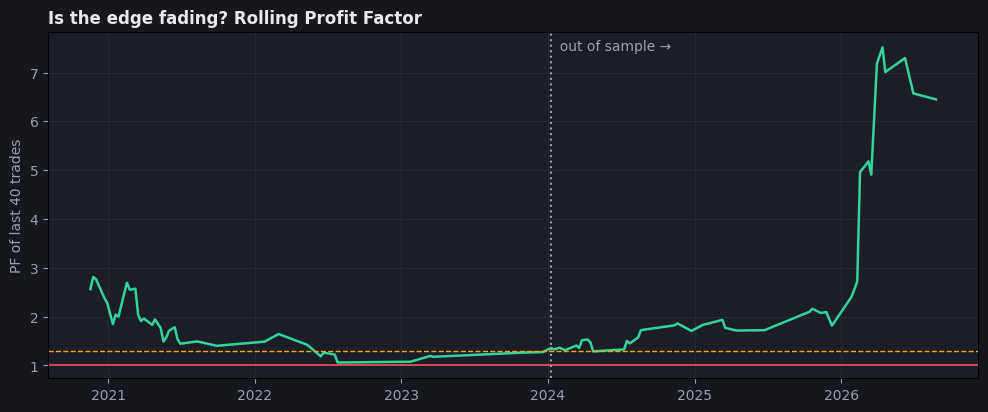

PF by year:


,n,pf,expectancy,win_rate,total_pnl
year,,,,,
2018,10,1.706,1.293,0.500,12.933
2019,17,4.776,2.401,0.706,40.810
2020,17,2.184,1.280,0.471,21.768
2021,21,1.171,0.434,0.429,9.117
2022,8,0.604,-1.885,0.375,-15.077
2023,5,21.229,4.373,0.800,21.867
2024,18,7.777,2.404,0.778,43.266
2025,11,2.257,0.591,0.818,6.505
2026,11,20.643,1.667,0.818,18.336


Recent years [2023, 2024, 2025] PF 6.666 vs historical PF 1.501 | expectancy ratio 2.21 | decay warning: False

Reference (in-sample trades): mu0 = +1.172%, sigma0 = 6.129%, n = 78
z today = +0.13 (green) | minimum z = -1.47 on 2022-06-21
Traded Mondays since OOS start by zone: {'green': 40, 'red': 0, 'yellow': 0}


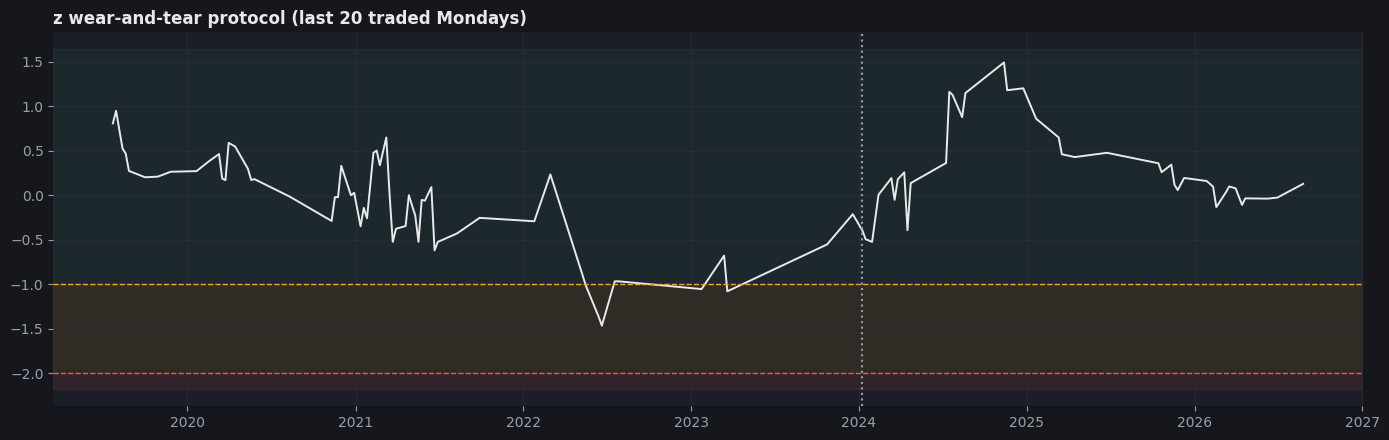

In [12]:
roll = rolling_pf(trades_all, window=40)
plot_rolling_pf(roll, oos_start=oos_start, window=40)

py = pf_by_year(trades_all)
print("PF by year:")
display(py.round(3))
ed = edge_decay_summary(trades_all)
print(f"Recent years {ed['recent_years']} PF {ed['recent']['pf']:.3f} vs historical PF {ed['historical']['pf']:.3f} | "
      f"expectancy ratio {ed['expectancy_ratio']:.2f} | decay warning: {ed['warning']}")

# ---- z protocol ----
W = 20
ref = trades_all.loc[pd.to_datetime(trades_all["entry_time"]) < OOS_START, "pnl"]
mu0, sd0 = float(ref.mean()), float(ref.std(ddof=1))
s = trades_all.set_index(pd.to_datetime(trades_all["exit_time"]))["pnl"]
z = (s.rolling(W).mean() - mu0) / (sd0 / np.sqrt(W))
zc = z.dropna()
zone = pd.cut(zc, [-np.inf, -2, -1, np.inf], labels=["red", "yellow", "green"])
after = zone[zc.index >= oos_start]
print(f"\nReference (in-sample trades): mu0 = {mu0:+.3f}%, sigma0 = {sd0:.3f}%, n = {len(ref)}")
print(f"z today = {zc.iloc[-1]:+.2f} ({zone.iloc[-1]}) | minimum z = {zc.min():+.2f} on {zc.idxmin():%Y-%m-%d}")
print(f"Traded Mondays since OOS start by zone: {after.value_counts().to_dict()}")

fig, ax = plt.subplots(figsize=(14, 4.5), facecolor=BG)
dark_ax(ax)
ax.plot(zc.index, zc, color=TXT, lw=1.4)
ax.axhspan(-1, ax.get_ylim()[1], color=GREEN, alpha=0.06); ax.axhspan(-2, -1, color=ORANGE, alpha=0.10); ax.axhspan(ax.get_ylim()[0], -2, color=RED, alpha=0.10)
ax.axhline(-1, color=ORANGE, ls="--", lw=1); ax.axhline(-2, color=RED, ls="--", lw=1)
ax.axvline(oos_start, color=SUB, ls=":")
ax.set_title("z wear-and-tear protocol (last 20 traded Mondays)", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

## 8. FULL VALIDATION GATE RUN (AUTOMATED MULTI-PHASE AUDIT)

The plateau phase needs the in-sample grid, so it is rebuilt here with the same window logic as notebook 02. The official verdict is the robot's sizing; the 30 % run is shown for transparency.

In [13]:
common_start = max(d.index[d["atr_rank"].notna()][0] for d in preps.values())
is_dfs = {L: d[(d.index >= common_start) & (d.index < OOS_START)] for L, d in preps.items()}

def evaluate_gate(pctl, L):
    t = eng.run_monday_backtest(is_dfs[L], **{**RULES, "atr_pctl": pctl, "atr_len": L})
    return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))

pf_grid, n_grid = grid_search(evaluate_gate, PCTLS, ATR_LENS)

validations = {}
for i, (k, f) in enumerate(SIZES.items(), 1):
    print("\n" + "=" * 70)
    print(f"{i}. VALIDATION GATE: {k} SIZING" + (" (OFFICIAL VERDICT)" if k == OFFICIAL else " (FOR TRANSPARENCY)"))
    print("=" * 70)
    validations[k] = run_validation(
        trades_df=scaled(trades_all, f), df_prices=df, eligible=elig_A, grid_pf=pf_grid, grid_n=n_grid, chosen=CHOSEN,
        oos_start=oos_start, mode="compound", mtm_paths=paths[k],
        monkey_entry_col="open", monkey_exit_col="open", monkey_cost_pct_per_side=COST_BPS / 100.0, verbose=True)
validation = validations[OFFICIAL]


1. VALIDATION GATE: 20% (robot) SIZING (OFFICIAL VERDICT)
VALIDATION GATE
[PASS] 1_oos: {'n': 40, 'pf': np.float64(6.451), 'pf_without_best_trade': np.float64(5.636), 'max_dd': -0.019, 'dd_basis': 'mtm'}
[PASS] 2_monte_carlo: {'ret_p5': 0.157, 'mdd_p5': -0.112, 'prob_ruin': 0.0, 'dd_basis': 'mtm'}
[PASS] 3_monkey: {'pf_real': 2.047, 'pct_pf': 0.99}
[PASS] 4_plateau: {'center_pf': 1.706, 'plateau': True, 'worst_drop_pct': 13.606}
[INFO] 5_edge_decay: {'recent_pf': 6.666, 'historical_pf': 1.501, 'warning': False}
------------------------------------------------------------ 
OVERALL: PASSED

2. VALIDATION GATE: 30% SIZING (FOR TRANSPARENCY)
VALIDATION GATE
[PASS] 1_oos: {'n': 40, 'pf': np.float64(6.451), 'pf_without_best_trade': np.float64(5.636), 'max_dd': -0.029, 'dd_basis': 'mtm'}
[PASS] 2_monte_carlo: {'ret_p5': 0.24, 'mdd_p5': -0.163, 'prob_ruin': 0.0, 'dd_basis': 'mtm'}
[PASS] 3_monkey: {'pf_real': 2.047, 'pct_pf': 0.99}
[PASS] 4_plateau: {'center_pf': 1.706, 'plateau': True, 'wors

## 9. STRATEGY METRICS DEFINITION & VERDICT

In [14]:
ret_series = eng.daily_returns(df, trades_all, sizing="fraction")
eq_series = (1.0 + ret_series).cumprod()
metrics = {"sharpe": float(sharpe_ratio(ret_series, periods_per_year=PPY)),
           "max_drawdown": float(max_drawdown(eq_series)),
           "num_trades": int(len(trades_all))}

print("=" * 70)
print(f"FINAL STRATEGY METRICS ({OFFICIAL} SIZING, WHOLE PERIOD)")
print("=" * 70)
print(f"Sharpe Ratio : {metrics['sharpe']:.2f}")
print(f"Max Drawdown : {metrics['max_drawdown'] * 100:.2f}%")
print(f"Total Trades : {metrics['num_trades']}")
print(f"Validation Gate Overall ({OFFICIAL}): {validation['status']}")

ph = validation["phases"]
mdd_p5 = ph["2_monte_carlo"]["mdd_p5"]
mc_margin_ok = bool(mdd_p5 > GATE["mc_mdd_p5_min"] - 0.01)
print("\n" + "=" * 70)
print("VERDICT SUMMARY")
print("=" * 70)
def tag(p):
    return "INFO" if p.get("informational") else ("SKIP" if p.get("skipped") else ("PASS" if p["passed"] else "FAIL"))
for name, p in ph.items():
    print(f"[{tag(p)}] {name}")
for k, v in validations.items():
    print(f"Gate at {k}: {v['status']} (failed: {[n for n, p in v['phases'].items() if 'passed' in p and not p['passed']]})")
print(f"Walk-forward gate: {'PASSED' if wf_pass else 'FAILED'} | stress (x2 costs and ex best years keep PF >= 1): {'OK' if stress_ok else 'NOT OK'}")
print(f"Monkey B (filter vs random Mondays): beats {mk_B['pct_pf'] * 100:.1f}% (diagnostic, not a gate phase)")
print(f"Monte Carlo mdd_p5 at {OFFICIAL}: {mdd_p5 * 100:.2f}% | limit {GATE['mc_mdd_p5_min'] * 100:.0f}% | passes with the 1-point margin used in the manual: {mc_margin_ok}")
print(f"Cost break-even: ~{breakeven_bps:.0f} bps per side | z today: {zc.iloc[-1]:+.2f} ({zone.iloc[-1]})")
print()
print("OVERALL (official run, strict gate): " + validation["status"] + (". Edge confirmed for the next stage." if validation["passed"] else ". Do not promote without documenting the failed phases (a margin or an exception must be declared, not silently applied)."))

FINAL STRATEGY METRICS (20% (robot) SIZING, WHOLE PERIOD)
Sharpe Ratio : 0.90
Max Drawdown : -6.56%
Total Trades : 118
Validation Gate Overall (20% (robot)): PASSED

VERDICT SUMMARY
[PASS] 1_oos
[PASS] 2_monte_carlo
[PASS] 3_monkey
[PASS] 4_plateau
[INFO] 5_edge_decay
Gate at 20% (robot): PASSED (failed: [])
Gate at 30%: PASSED (failed: [])
Walk-forward gate: PASSED | stress (x2 costs and ex best years keep PF >= 1): OK
Monkey B (filter vs random Mondays): beats 97.9% (diagnostic, not a gate phase)
Monte Carlo mdd_p5 at 20% (robot): -11.17% | limit -25% | passes with the 1-point margin used in the manual: True
Cost break-even: ~73 bps per side | z today: +0.13 (green)

OVERALL (official run, strict gate): PASSED. Edge confirmed for the next stage.


## 10. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [15]:
def _scalars(p):
    return {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, np.generic))}

save_json(cfg, "03_validation.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "official_sizing": OFFICIAL,
    "status": {k: v["status"] for k, v in validations.items()},
    "metrics": metrics,
    "phases": {k: {n: _scalars(p) for n, p in v["phases"].items()} for k, v in validations.items()},
    "walk_forward": {"efficiency": float(efficiency), "pct_positive_years": pct_positive_years, "worst_mdd": worst_oos_mdd, "passed": wf_pass},
    "monkey": {"A_pct_pf": mk_A["pct_pf"], "B_pct_pf": mk_B["pct_pf"]},
    "monte_carlo_mdd_p5": {k: m["mdd_p5"] for k, m in mcs.items()},
    "mc_passes_with_1pt_margin": mc_margin_ok,
    "cost_breakeven_bps_per_side": float(breakeven_bps),
    "cost_sweep": cost_tbl.reset_index().to_dict(orient="records"),
    "profit_share_top10pct_trades": share_top10,
    "z_protocol": {"mu0": mu0, "sigma0": sd0, "z_today": float(zc.iloc[-1]), "zone_today": str(zone.iloc[-1]), "z_min": float(zc.min())},
    "edge_decay_warning": bool(ed["warning"]),
    "stress_ok": stress_ok,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd/03_validation.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/runs/v1_btcusd/03_validation.json')